In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import flap
import flap_w7x_abes
import h5py
from poloidal_flow import ABESConfig, ABESDataReader

mpl.rcParams.update({
    'font.size': 14
})

INIT flap storage
Importing flap_w7x_abes
Importing w7x_webapi


In [2]:
# ABES Spatial calibration
dev_r = ABESDataReader(
    ABESConfig('20250409.046', True)
).read_spatial_calibration()

r_lcfs = 6.25

with h5py.File(f'../processed_data/elliptical/20250409.046/20250409.046_elliptical.h5', 'r') as f:   
    abes_v = f['ccf_data/poloidal_velocity'][:]   
    abes_v_error = f['ccf_data/poloidal_velocity_err'][:]

doppler_low = np.loadtxt('doppler/20250409.45_QMR-W1_sweep_7_low_ECRH.txt')
doppler_high = np.loadtxt('doppler/20250409.45_QMR-W1_sweep_12_high_ECRH.txt')

doppler_low_r = np.sqrt(doppler_low[:, 0]**2 + doppler_low[:, 1]**2)
doppler_high_r = np.sqrt(doppler_high[:, 0]**2 + doppler_high[:, 1]**2)

doppler_low_v = doppler_low[:, 3]
doppler_high_v = doppler_high[:, 3]
doppler_low_v_err = doppler_low[:, 4]
doppler_high_v_err = doppler_high[:, 4]

doppler_low_sort_idx = np.argsort(doppler_low_r)
doppler_high_sort_idx = np.argsort(doppler_high_r)

doppler_low_r = doppler_low_r[doppler_low_sort_idx]
doppler_high_r = doppler_high_r[doppler_high_sort_idx]
doppler_low_v = doppler_low_v[doppler_low_sort_idx]
doppler_high_v = doppler_high_v[doppler_high_sort_idx]
doppler_low_v_err = doppler_low_v_err[doppler_low_sort_idx]
doppler_high_v_err = doppler_high_v_err[doppler_high_sort_idx]

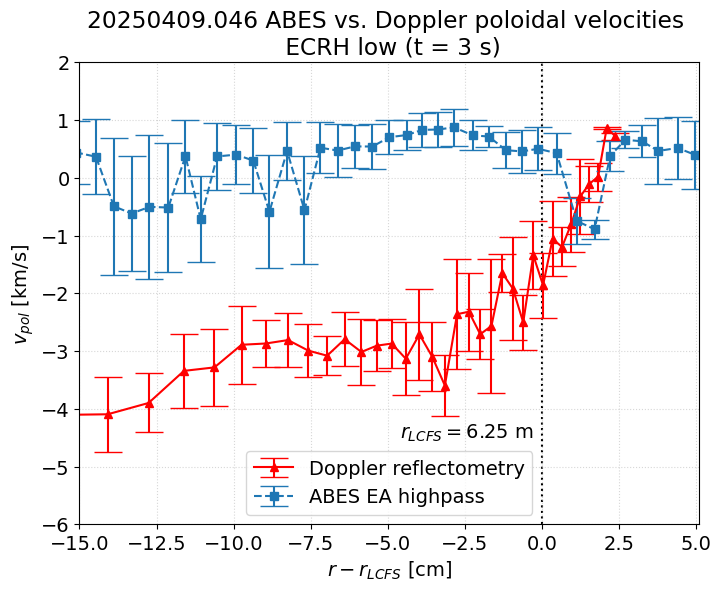

In [3]:
fig, ax = plt.subplots(figsize = (8, 6))

ax.set_title('20250409.046 ABES vs. Doppler poloidal velocities \n ECRH low (t = 3 s)')
ax.set_xlabel('$r - r_{LCFS}$ [cm]')
ax.set_ylabel('$v_{pol}$ [km/s]')
ax.set_xlim(-15, 5.1)

ax.axvline(0, c = 'k', ls = 'dotted', zorder = 1)

ax.errorbar((doppler_low_r - r_lcfs)*100, doppler_low_v, yerr = doppler_low_v_err, capsize = 10, marker = '^', c = 'r', label = 'Doppler reflectometry')
ax.errorbar((dev_r - r_lcfs)*100, abes_v[30, :], yerr = abes_v_error[30, :], capsize = 10, marker = 's', ls = 'dashed', label = 'ABES EA highpass')

ax.text(-4.6, -4.5, s = '$r_{LCFS} = 6.25$ m', fontsize = 14)

ax.grid(alpha = 0.5, ls = 'dotted')
ax.legend()

ax.set_ylim(-6, 2)

plt.savefig('../plots/abes_v_doppler_ecrh_low.pdf')

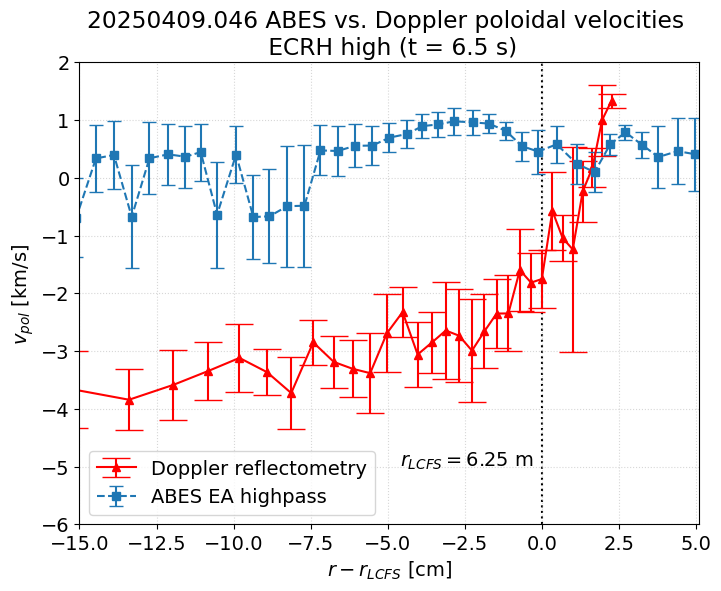

In [4]:
fig, ax = plt.subplots(figsize = (8, 6))

ax.set_title('20250409.046 ABES vs. Doppler poloidal velocities \n ECRH high (t = 6.5 s)')
ax.set_xlabel('$r - r_{LCFS}$ [cm]')
ax.set_ylabel('$v_{pol}$ [km/s]')
ax.set_xlim(-15, 5.1)

ax.axvline(0, c = 'k', ls = 'dotted', zorder = 1)

ax.errorbar((doppler_high_r - r_lcfs)*100, doppler_high_v, yerr = doppler_high_v_err, capsize = 10, marker = '^', c = 'r', label = 'Doppler reflectometry')
ax.errorbar((dev_r - r_lcfs)*100, abes_v[65, :], yerr = abes_v_error[65, :], capsize = 5, marker = 's', ls = 'dashed', label = 'ABES EA highpass')

ax.text(-4.6, -5, s = '$r_{LCFS} = 6.25$ m', fontsize = 14)

ax.grid(alpha = 0.5, ls = 'dotted')
ax.legend()

ax.set_ylim(-6, 2)

plt.savefig('../plots/abes_v_doppler_ecrh_high.pdf')

## Time averaged velocity profiles

In [8]:
v_avg_26 = np.mean(abes_v[20:60], axis = 0)
v_avg_67 = np.mean(abes_v[60:70], axis = 0)
v_avg_78 = np.mean(abes_v[70:80], axis = 0)

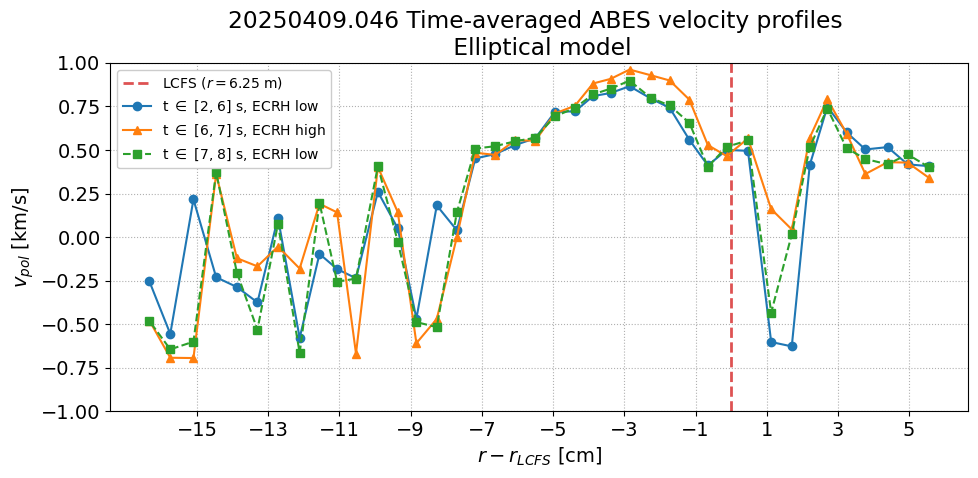

In [62]:
plt.figure(figsize = (10, 5))
plt.title('20250409.046 Time-averaged ABES velocity profiles \n Elliptical model')

plt.axvline(0, ls = 'dashed', alpha = 0.8, lw = 2, label = 'LCFS ($r = 6.25$ m)', color = 'tab:red')

plt.plot((dev_r - 6.25) * 100, v_avg_26, marker = 'o', label = 't $\\in$ [2, 6] s, ECRH low')
plt.plot((dev_r - 6.25) * 100, v_avg_67, marker = '^', label = 't $\\in$ [6, 7] s, ECRH high')
plt.plot((dev_r - 6.25) * 100, v_avg_78, marker = 's', ls = 'dashed', label = 't $\\in$ [7, 8] s, ECRH low')

plt.ylim(-1, 1)
plt.xticks(np.linspace(-15, 5, 11))

plt.xlabel('$r - r_{LCFS}$ [cm]')
plt.ylabel('$v_{pol}$ [km/s]')

plt.grid(ls = 'dotted')
plt.legend(fontsize = 10, framealpha = True)

plt.tight_layout()
plt.savefig('time_averaged_velocities.pdf')